# Assignment 2 — GitHub Activity Data Audit (Re-runnable EDA)

**NYCU · Big Data Analytics Techniques and Applications · Fall 2026**  
**Notebook purpose:** Understand the official eight-table dataset before building a prediction model. Re-run this **same notebook** after every new course-data snapshot to recompute statistics and compare releases.

> **Data provenance:** This notebook reads **only local files from the instructor's `assignment2/data/db/` directory** and the official `evaluation/test_input.csv` when available. It does **not** query the GitHub API, GH Archive, websites, or any other data source. Its charts and tables are computed at execution time; values are **not** prefilled from old releases.

### What you will get

1. Release fingerprint, table sizes, schemas, primary keys, and time coverage.
2. Cohort identification, optional bot characterization, and FK integrity checks.
3. Weekly volumes and user participation for six activity-related signals.
4. Point-in-time diagnostics that expose common leakage hazards.
5. A feasible framework for *future* historical-label construction, with uncertainties identified rather than hidden.
6. Optional **append-only snapshot audit log** under your own project's `experiments/` (never inside the instructor's directory).

### What this notebook does **not** do

It does **not** train a model, fabricate exact target labels from imperfect timestamp proxies, or submit predictions. The next engineering milestone is a separately tested point-in-time dataset builder.

**Usage:** Save as `Assignment 2/notebooks/01_data_audit.ipynb` and run **Restart Kernel and Run All** after updating `Assignment 2/assignment2/`. Starting the notebook from the project root or `notebooks/` works; you can also set an explicit path below.

## 0. Assignment contract (read first)

| Requirement | Official specification |
|---|---|
| Nature | Individual; **15%** of semester grade |
| Deadline | **2026-11-11 23:55, Asia/Taipei**; no late submissions |
| Task | For each official test `UserID`, predict presence/absence of **six activities** in `[2026-11-12 00:00, 2026-11-19 00:00)` **Taiwan time** |
| Targets | `open_pr`, `open_issue`, `issue_comment`, `pr_review`, `pr_review_comment`, `push` |
| Scoring | **7%**: `(macro-F1 + micro-F1) / 2` over six outputs |
| Presentation | **8%**: 8–12-minute real recording; **English slides ≤10 pages**; address Q1–Q4 |
| Final CSV | `output_{studentID}.csv`; exact 7 columns, one row per test user, binary predictions |
| Code | Public GitHub repository with full runnable code and `README.md`; commits before deadline |
| Data constraint | **Only data in the official assignment repository. No external collection or GitHub API.** |
| Validation | **Temporal split**, not random; no access to rows or late-known values before historical cutoff |
| Daily release | **21:00 Asia/Taipei**, October 14–November 11; final release **Nov 11 at 21:00**, data through **20:00** |

**Graded questions:** Q1 (1%): complete schema graph + instance graph for GitHub IDs `22996444`, `28983449` during `2026-09-15 00:00`–`2026-09-17 00:00 UTC`. Q2 (2%): relationship modeling improvements. Q3 (2%): temporal modeling improvements. Q4 (3%): framework diagram and full pipeline. These questions are not answered by EDA alone.

**References**
- [Original assignment instructions](../Big%20Data%20Course%20-%20Assignment%202.pdf) (in project root if kept there; otherwise use your local copy).
- [Official assignment repository](https://github.com/nycubigdata-2026fall/BigData2026-Assignment2)
- [Official data README](https://github.com/nycubigdata-2026fall/BigData2026-Assignment2/blob/main/data/README.md)
- [Official SCHEMA.md](https://github.com/nycubigdata-2026fall/BigData2026-Assignment2/blob/main/data/db/SCHEMA.md)
- [Official evaluation README](https://github.com/nycubigdata-2026fall/BigData2026-Assignment2/blob/main/evaluation/README.md)

**Do not confuse:** `first_seen_at` (row became observable) with `created_at` / `submitted_at` (underlying event time). For PRs, issues and reviews, these may differ substantially.

## 1. Environment, paths, and update settings

This notebook deliberately has **no cached processed dataset**. Every run reads the current Parquet files afresh. For a new daily release, stop any running notebook kernels that are using the dataset, replace the **entire ignored instructor clone** with a fresh clone, and then restart/rerun this notebook.

```powershell
# In your personal project's root directory (only after your own code is outside assignment2/)
Remove-Item -Recurse -Force .\assignment2
git clone --depth 1 https://github.com/nycubigdata-2026fall/BigData2026-Assignment2.git assignment2
```

The instructor **force-replaces** history and recommends cloning again, **not `git pull`**. Preserve a separate archived copy if you need to reproduce historical snapshots. The notebook never deletes or updates the instructor's data.

Create and activate the provided Conda environment once from your project root:

```powershell
conda env create -f environment.yaml
conda activate nycu-bda-asg2
python -m ipykernel install --user --name nycu-bda-asg2 --display-name "Python (NYCU BDA A2)"
```

Choose the **Python (NYCU BDA A2)** kernel in JupyterLab / VS Code. Alternatively, install `pandas`, `pyarrow`, `numpy`, `matplotlib`, and a Jupyter kernel into your existing environment. You only need to install dependencies once, not on every dataset refresh.

**Settings**
- `DATA_DIR_OVERRIDE`: optional absolute directory to `.../assignment2/data/db` (Windows paths work).
- `SAVE_RELEASE_HISTORY`: when enabled, write a small local log to `experiments/eda_snapshot_history.jsonl` only when a new fingerprint is found.
- `AUDIT_TIME_TW`: an example cutoff for leakage diagnostics; **not** a train/test split.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import subprocess
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    import pyarrow.parquet as pq
except ImportError as exc:
    raise ImportError(
        "Parquet support requires pyarrow. Install it in THIS notebook's kernel "
        "using `%pip install pyarrow` (then restart kernel) or "
        "`python -m pip install pyarrow` in your selected environment."
    ) from exc

# Edit only if the automatic search does not find your local clone.
DATA_DIR_OVERRIDE = os.environ.get("ASG2_DATA_DIR", "").strip()  # e.g. r"C:\...\Assignment 2\assignment2\data\db"
SAVE_RELEASE_HISTORY = True
AUDIT_TIME_TW = "2026-10-01 00:00:00"
LOCAL_TZ = "Asia/Taipei"

# Shared cutoff for all diagnostic sections (7b, 7c, and 10).
# Keep this near configuration so later cells do not reference an undefined cutoff.
def parse_audit_cutoff(value):
    t = pd.Timestamp(value)
    return t.tz_localize(LOCAL_TZ) if t.tzinfo is None else t.tz_convert(LOCAL_TZ)

cutoff_taiwan = parse_audit_cutoff(AUDIT_TIME_TW)
cutoff_utc = cutoff_taiwan.tz_convert("UTC")
TABLES = (
    "Users", "Repositories", "PullRequests", "Issues", "IssueComments",
    "PRReviews", "PRReviewComments", "Pushes",
)
ROW_TIME = {
    "Users": "first_seen_at", "Repositories": "first_seen_at",
    "PullRequests": "first_seen_at", "Issues": "first_seen_at",
    "IssueComments": "created_at", "PRReviews": "first_seen_at",
    "PRReviewComments": "created_at", "Pushes": "created_at",
}
PRIMARY_KEY = {
    "Users": "user_id", "Repositories": "repo_id", "PullRequests": "pr_id",
    "Issues": "issue_id", "IssueComments": "comment_id", "PRReviews": "review_id",
    "PRReviewComments": "comment_id", "Pushes": "push_id",
}

def locate_db(override=""):
    if override:
        p = Path(override).expanduser().resolve()
        options = (p, p / "db", p / "data" / "db", p / "assignment2" / "data" / "db")
    else:
        places = [Path.cwd(), *Path.cwd().parents]
        options = [cand for root in places for cand in (
            root / "assignment2" / "data" / "db",
            root / "data" / "db",
        )]
    for p in options:
        if all((p / f"{name}.parquet").is_file() for name in TABLES):
            return p
    raise FileNotFoundError(
        "Cannot find all eight official Parquet files. Put the notebook in "
        "<project>/notebooks/ with the instructor clone at "
        "<project>/assignment2/data/db/, or set DATA_DIR_OVERRIDE / ASG2_DATA_DIR. "
        f"Current working directory: {Path.cwd()}"
    )

DATA_DIR = locate_db(DATA_DIR_OVERRIDE)
OFFICIAL_REPO = DATA_DIR.parent.parent
PROJECT_ROOT = OFFICIAL_REPO.parent
HISTORY_PATH = PROJECT_ROOT / "experiments" / "eda_snapshot_history.jsonl"
print("Notebook working directory:", Path.cwd())
print("Detected project root:     ", PROJECT_ROOT)
print("Official data directory:  ", DATA_DIR)
print("Snapshot log (optional):  ", HISTORY_PATH)
print("pandas / NumPy / pyarrow: ", pd.__version__, np.__version__, pq.__version__ if hasattr(pq, "__version__") else "installed")

Notebook working directory: c:\Users\Davon\Desktop\Master\Semester 3\535703 Big Data Analytics\Assignment 2\notebooks
Detected project root:      c:\Users\Davon\Desktop\Master\Semester 3\535703 Big Data Analytics\Assignment 2
Official data directory:   c:\Users\Davon\Desktop\Master\Semester 3\535703 Big Data Analytics\Assignment 2\assignment2\data\db
Snapshot log (optional):   c:\Users\Davon\Desktop\Master\Semester 3\535703 Big Data Analytics\Assignment 2\experiments\eda_snapshot_history.jsonl
pandas / NumPy / pyarrow:  2.3.3 2.4.6 installed


## 2. Source freshness and release identification

The **published release time (21:00 Taiwan)** is different from the **newest event time** in an individual table. A table without activity near the cutoff is not necessarily stale. We record:

- The official clone's Git `HEAD`, when the nested `.git` directory exists.
- File sizes and filesystem modification timestamps.
- Row counts from Parquet metadata (without loading full tables).

**Important:** A new local modification timestamp alone does not prove there is new upstream data (re-cloning can refresh timestamps). A Git SHA is more reliable for identifying a published snapshot. These measurements describe your local copy; they do not verify the instructor's remote has already released today's version.

In [2]:
def git_commit(repo):
    if not (repo / ".git").exists():
        return None
    try:
        result = subprocess.run(
            ["git", "-C", str(repo), "rev-parse", "HEAD"],
            capture_output=True, text=True, check=True, timeout=5,
        )
        return result.stdout.strip()
    except (OSError, subprocess.SubprocessError):
        return None

REPO_SHA = git_commit(OFFICIAL_REPO)
meta_rows = []
parquet_columns = {}
for name in TABLES:
    path = DATA_DIR / f"{name}.parquet"
    pf = pq.ParquetFile(path)
    parquet_columns[name] = list(pf.schema_arrow.names)
    stat = path.stat()
    meta_rows.append({
        "table": name,
        "rows": pf.metadata.num_rows,
        "columns": len(pf.schema_arrow.names),
        "row_groups": pf.metadata.num_row_groups,
        "file_MB": round(stat.st_size / 1_000_000, 2),
        "file_modified_local": pd.Timestamp(stat.st_mtime, unit="s", tz="UTC")
                            .tz_convert(LOCAL_TZ).strftime("%Y-%m-%d %H:%M:%S %Z"),
        "bytes": stat.st_size,
        "mtime_ns": stat.st_mtime_ns,
    })
metadata_df = pd.DataFrame(meta_rows)
file_signature = [
    (r["table"], r["bytes"], r["mtime_ns"]) for r in meta_rows
]
SNAPSHOT_FINGERPRINT = REPO_SHA or hashlib.sha256(
    json.dumps(file_signature).encode("utf-8")
).hexdigest()
print("Official clone HEAD:", REPO_SHA or "Not detected; using local file metadata fingerprint")
print("Snapshot fingerprint:", SNAPSHOT_FINGERPRINT)
display(metadata_df.drop(columns=["bytes", "mtime_ns"]).set_index("table"))

expected_files = [f"{n}.parquet" for n in TABLES]
assert len(expected_files) == len(set(expected_files)) == 8

Official clone HEAD: 506d860693df60a698b68aa63a8edb4a984c8e1b
Snapshot fingerprint: 506d860693df60a698b68aa63a8edb4a984c8e1b


,rows,columns,row_groups,file_MB,file_modified_local
table,,,,,
Users,45590,6,1,1.26,2026-10-14 10:21:49 CST
Repositories,109081,7,1,4.33,2026-10-14 10:21:49 CST
PullRequests,301518,18,1,26.75,2026-10-14 10:21:49 CST
Issues,172007,20,1,66.40,2026-10-14 10:21:49 CST
IssueComments,106204,10,1,18.88,2026-10-14 10:21:48 CST
PRReviews,90710,12,1,7.37,2026-10-14 10:21:49 CST
PRReviewComments,66422,17,1,21.06,2026-10-14 10:21:49 CST
Pushes,1661256,10,2,42.84,2026-10-14 10:21:49 CST


## 3. Actual schema and representative rows

The assignment describes eight tables linked by PK/FK relationships. The full authoritative schema is `assignment2/data/db/SCHEMA.md`. The following cells inspect **the files actually on disk**, rather than relying on static example dimensions.

For efficiency, we read **only lightweight columns** for examples. Large `body`, `diff_hunk`, and similar text fields are not loaded automatically.

In [3]:
SCHEMA_ROLES = {
    "Users": {"PK": "user_id", "FK": []},
    "Repositories": {"PK": "repo_id", "FK": []},
    "PullRequests": {"PK": "pr_id", "FK": ["repo_id", "author_id", "merged_by_id"]},
    "Issues": {"PK": "issue_id", "FK": ["repo_id", "author_id", "pull_request_id", "assignee_id"]},
    "IssueComments": {"PK": "comment_id", "FK": ["issue_id", "repo_id", "author_id"]},
    "PRReviews": {"PK": "review_id", "FK": ["pr_id", "repo_id", "reviewer_id"]},
    "PRReviewComments": {"PK": "comment_id", "FK": [
        "pr_id", "repo_id", "author_id", "pull_request_review_id", "in_reply_to_id"
    ]},
    "Pushes": {"PK": "push_id", "FK": ["user_id", "repo_id"]},
}

def read_cols(table, cols):
    # Read selected columns only. Never cache data between notebook runs.
    available = set(parquet_columns[table])
    missing = set(cols) - available
    if missing:
        raise KeyError(f"{table}.parquet missing expected columns: {sorted(missing)}")
    return pd.read_parquet(DATA_DIR / f"{table}.parquet", columns=list(dict.fromkeys(cols)))

schema_records = []
for table in TABLES:
    schema = pq.ParquetFile(DATA_DIR / f"{table}.parquet").schema_arrow
    for field in schema:
        role = "PK" if field.name == PRIMARY_KEY[table] else (
            "FK" if field.name in SCHEMA_ROLES[table]["FK"] else (
            "ROW TIME" if field.name == ROW_TIME[table] else ""
        ))
        schema_records.append({"table": table, "column": field.name, "parquet_dtype": str(field.type), "role": role})
schema_df = pd.DataFrame(schema_records)
display(schema_df)

for table in TABLES:
    example = read_cols(table, [c for c in [PRIMARY_KEY[table], ROW_TIME[table], *SCHEMA_ROLES[table]["FK"]]
                                if c in parquet_columns[table]])
    display(Markdown(f"**{table}: representative early rows** (tables are chronological; not random samples)"))
    display(example.head(3))

,table,column,parquet_dtype,role
0,Users,user_id,int64,PK
1,Users,github_user_id,int64,
2,Users,login,large_string,
3,Users,is_bot,bool,
4,Users,is_cohort,bool,
...,...,...,...,...
95,Pushes,ref_type,large_string,
96,Pushes,branch,large_string,
97,Pushes,is_new_ref,bool,
98,Pushes,created_at,timestamp[ns],ROW TIME


**Users: representative early rows** (tables are chronological; not random samples)

,user_id,first_seen_at
0,0,2025-12-01 00:01:12
1,1,2025-12-01 00:01:17
2,2,2025-12-01 00:01:38


**Repositories: representative early rows** (tables are chronological; not random samples)

,repo_id,first_seen_at
0,0,2025-12-01 00:01:12
1,1,2025-12-01 00:01:17
2,2,2025-12-01 00:01:38


**PullRequests: representative early rows** (tables are chronological; not random samples)

... (7 outputs left out)

**PRReviewComments: representative early rows** (tables are chronological; not random samples)

,comment_id,created_at,pr_id,repo_id,author_id,pull_request_review_id,in_reply_to_id
0,0,2025-12-01 00:30:42,25,23,25,1,<NA>
1,1,2025-12-01 00:36:34,9,82,77,<NA>,<NA>
2,2,2025-12-01 00:45:50,11,96,89,<NA>,<NA>


**Pushes: representative early rows** (tables are chronological; not random samples)

,push_id,created_at,user_id,repo_id
0,0,2025-12-01 00:01:12,0,0
1,1,2025-12-01 00:01:17,1,1
2,2,2025-12-01 00:01:17,1,1


## 4. PK/FK graph and structural integrity

Official rules: PKs are **row numbers** and FK values point to those rows. They may be **renumbered between daily releases**. Stable identities must use the original GitHub IDs (`github_user_id` etc.).

```text
Users ◄──── PullRequests ────► Repositories
  ▲               ▲                ▲
  │               │                │
  ├──── Issues ───┼────────────────┤
  │       ▲       │                │
  ├── IssueComments ───────────────┤
  │               │                │
  ├──── PRReviews ┴────────────────┤
  │         ▲     ▲                │
  ├── PRReviewComments ────────────┤
  │         └─ self-reply FK       │
  └────────── Pushes ──────────────┘
```

The diagram is a **conceptual sketch**; the audit below checks the **full list of all 20 FK columns**, including `PullRequests.merged_by_id`, `Issues.assignee_id`, and `PRReviewComments.in_reply_to_id`.

A null FK is often expected (e.g., missing PR author or review linkage), not automatically a defect. A **non-null FK referencing no PK in the same snapshot** is more suspicious. The full FK audit scans only PK/FK columns, not large text content.

In [4]:
FK_EDGES = [
    ("PullRequests", "repo_id", "Repositories"),
    ("PullRequests", "author_id", "Users"),
    ("PullRequests", "merged_by_id", "Users"),
    ("Issues", "repo_id", "Repositories"),
    ("Issues", "author_id", "Users"),
    ("Issues", "pull_request_id", "PullRequests"),
    ("Issues", "assignee_id", "Users"),
    ("IssueComments", "issue_id", "Issues"),
    ("IssueComments", "repo_id", "Repositories"),
    ("IssueComments", "author_id", "Users"),
    ("PRReviews", "pr_id", "PullRequests"),
    ("PRReviews", "repo_id", "Repositories"),
    ("PRReviews", "reviewer_id", "Users"),
    ("PRReviewComments", "pr_id", "PullRequests"),
    ("PRReviewComments", "repo_id", "Repositories"),
    ("PRReviewComments", "author_id", "Users"),
    ("PRReviewComments", "pull_request_review_id", "PRReviews"),
    ("PRReviewComments", "in_reply_to_id", "PRReviewComments"),
    ("Pushes", "user_id", "Users"),
    ("Pushes", "repo_id", "Repositories"),
]
assert len(FK_EDGES) == 20
pk_values = {}
pk_audit = []
for table in TABLES:
    key = PRIMARY_KEY[table]
    s = read_cols(table, [key])[key]
    pk_values[table] = pd.Index(s.dropna().unique())
    pk_audit.append({
        "table": table, "PK": key, "rows": len(s),
        "PK_null": int(s.isna().sum()), "PK_duplicates": int(s.duplicated().sum()),
    })
pk_audit_df = pd.DataFrame(pk_audit)
display(Markdown("**Primary-key checks**"))
display(pk_audit_df)

fk_rows = []
for table in TABLES:
    edges = [(fk, target) for src, fk, target in FK_EDGES if src == table]
    if not edges:
        continue
    df = read_cols(table, [fk for fk, _ in edges])
    for fk, target in edges:
        s = df[fk]
        is_present = s.notna()
        invalid = is_present & ~s.isin(pk_values[target])
        fk_rows.append({
            "table": table, "foreign_key": fk, "references": target + "." + PRIMARY_KEY[target],
            "non_null": int(is_present.sum()), "null_pct": round(100*s.isna().mean(), 2),
            "orphan_references": int(invalid.sum()),
        })
fk_audit_df = pd.DataFrame(fk_rows)
display(Markdown("**Foreign-key checks**"))
display(fk_audit_df)
print("Total PK duplicates:", int(pk_audit_df["PK_duplicates"].sum()))
print("Total non-null orphan FKs:", int(fk_audit_df["orphan_references"].sum()))

**Primary-key checks**

,table,PK,rows,PK_null,PK_duplicates
0,Users,user_id,45590,0,0
1,Repositories,repo_id,109081,0,0
2,PullRequests,pr_id,301518,0,0
3,Issues,issue_id,172007,0,0
4,IssueComments,comment_id,106204,0,0
5,PRReviews,review_id,90710,0,0
6,PRReviewComments,comment_id,66422,0,0
7,Pushes,push_id,1661256,0,0


**Foreign-key checks**

,table,foreign_key,references,non_null,null_pct,orphan_references
0,PullRequests,repo_id,Repositories.repo_id,301518,0.00,0
1,PullRequests,author_id,Users.user_id,135077,55.20,0
2,PullRequests,merged_by_id,Users.user_id,105179,65.12,0
3,Issues,repo_id,Repositories.repo_id,172007,0.00,0
4,Issues,author_id,Users.user_id,172007,0.00,0
5,Issues,pull_request_id,PullRequests.pr_id,15443,91.02,0
6,Issues,assignee_id,Users.user_id,39952,76.77,0
7,IssueComments,issue_id,Issues.issue_id,106204,0.00,0
8,IssueComments,repo_id,Repositories.repo_id,106204,0.00,0
9,IssueComments,author_id,Users.user_id,106204,0.00,0


Total PK duplicates: 0
Total non-null orphan FKs: 0


## 5. Cohort, identity consistency, and bots

The assignment's **9,000 collected users** are not identical to all rows in `Users`. The table also contains *other* users referenced by cohort events. Only `Users.is_cohort` marks users whose **own activity** was collected comprehensively. Use `github_user_id` (stable) in the official output, **not** the internal `user_id` (may change each release).

`is_bot` is a data attribute, not an instruction to exclude bots. Do not remove bots or anyone else from the official test list unless the assignment explicitly permits that.

In [5]:
users = read_cols("Users", ["user_id", "github_user_id", "login", "is_cohort", "is_bot", "first_seen_at"])
assert users["github_user_id"].notna().all(), "Stable github_user_id must be present"
print("Users table rows:          ", len(users))
print("Cohort users:             ", int(users["is_cohort"].sum()))
print("Other referenced users:   ", int((~users["is_cohort"]).sum()))
print("Bot accounts (all rows): ", int(users["is_bot"].sum()))
print("Duplicate GitHub user IDs:", int(users["github_user_id"].duplicated().sum()))
print("Duplicate internal IDs:   ", int(users["user_id"].duplicated().sum()))
cohort_users = users.loc[users["is_cohort"], ["user_id", "github_user_id", "is_bot"]].copy()
cohort_internal_ids = pd.Index(cohort_users["user_id"])
cohort_github_ids = pd.Index(cohort_users["github_user_id"])
display(users.groupby(["is_cohort", "is_bot"], dropna=False).size().rename("users").reset_index())
if len(cohort_users) != 9_000:
    print("NOTICE: Official cohort is described as 9,000. Investigate why this snapshot differs.")

Users table rows:           45590
Cohort users:              9000
Other referenced users:    36590
Bot accounts (all rows):  155
Duplicate GitHub user IDs: 0
Duplicate internal IDs:    0


,is_cohort,is_bot,users
0,False,False,36435
1,False,True,155
2,True,False,9000


## 6. Temporal coverage: what was observable when?

According to the official data README, **record existence for feature construction** is defined by:

- `first_seen_at` for `Users`, `Repositories`, `PullRequests`, `Issues`, `PRReviews`.
- `created_at` for `IssueComments`, `PRReviewComments`, `Pushes`.

All timestamps are **UTC encoded as timezone-naive values** in Parquet. Convert by **localizing to UTC first**, *then* converting to Taiwan time for plots. Do **not** localize them to Taiwan time.

Coverage charts refer to **rows newly observable by week**, not necessarily the original underlying creation date. For PRs/issues/reviews, that distinction matters for supervised-label construction.

,table,row_time,non_null_rows,null_pct,min_UTC,max_UTC,max_Taiwan
0,Users,first_seen_at,45590,0.0,2025-12-01 00:01:12+00:00,2026-10-13 12:51:56+00:00,2026-10-13 20:51:56+08:00
1,Repositories,first_seen_at,109081,0.0,2025-12-01 00:01:12+00:00,2026-10-13 12:56:36+00:00,2026-10-13 20:56:36+08:00
2,PullRequests,first_seen_at,301518,0.0,2025-12-01 00:03:36+00:00,2026-10-13 12:47:07+00:00,2026-10-13 20:47:07+08:00
3,Issues,first_seen_at,172007,0.0,2025-12-01 00:01:55+00:00,2026-10-13 12:51:56+00:00,2026-10-13 20:51:56+08:00
4,IssueComments,created_at,106204,0.0,2025-12-01 00:01:55+00:00,2026-10-13 12:38:07+00:00,2026-10-13 20:38:07+08:00
5,PRReviews,first_seen_at,90710,0.0,2025-12-01 00:26:48+00:00,2026-10-13 12:41:43+00:00,2026-10-13 20:41:43+08:00
6,PRReviewComments,created_at,66422,0.0,2025-12-01 00:30:42+00:00,2026-10-13 11:32:36+00:00,2026-10-13 19:32:36+08:00
7,Pushes,created_at,1661256,0.0,2025-12-01 00:01:12+00:00,2026-10-13 12:59:29+00:00,2026-10-13 20:59:29+08:00


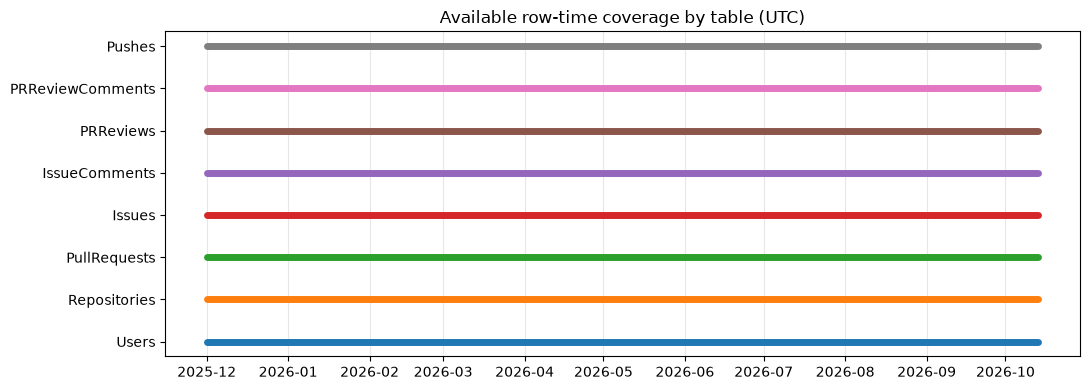

In [6]:
def as_utc(series):
    # Interpret timezone-naive timestamp values from the instructor files as UTC.
    return pd.to_datetime(series, errors="coerce", utc=True)

def local_week_start(utc_times):
    # Weekly Monday 00:00 in Asia/Taipei, displayed as local-naive dates.
    local = as_utc(utc_times).dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
    return local.dt.to_period("W-SUN").dt.start_time

coverage = []
for table in TABLES:
    t = as_utc(read_cols(table, [ROW_TIME[table]])[ROW_TIME[table]])
    coverage.append({
        "table": table, "row_time": ROW_TIME[table],
        "non_null_rows": int(t.notna().sum()), "null_pct": round(100*t.isna().mean(), 3),
        "min_UTC": t.min(), "max_UTC": t.max(),
        "max_Taiwan": t.max().tz_convert(LOCAL_TZ) if t.notna().any() else pd.NaT,
    })
coverage_df = pd.DataFrame(coverage)
display(coverage_df)
assert (coverage_df["null_pct"] == 0).all(), "Some row-time values are missing; investigate before modeling."

fig, ax = plt.subplots(figsize=(11, 4))
for i, r in enumerate(coverage):
    if pd.notna(r["min_UTC"]) and pd.notna(r["max_UTC"]):
        ax.plot([r["min_UTC"], r["max_UTC"]], [i, i], lw=5, solid_capstyle="round")
ax.set_yticks(range(len(TABLES)), TABLES)
ax.set_title("Available row-time coverage by table (UTC)")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

## 7. Activity signals: weekly volume and distinct cohort users

**Critical separation of concepts:**

| Target-like signal | Table / time | Interpret with caution |
|---|---|---|
| `open_pr` | `PullRequests.first_seen_at` | **First observed PR row**, **NOT proven newly opened PR** |
| `open_issue` | `Issues.first_seen_at` where `is_pull_request=False` | **First observed non-PR issue row**, not proven issue creation event |
| `issue_comment` | `IssueComments.created_at` | Direct observed comment timestamp |
| `pr_review` | `PRReviews.first_seen_at` | **First observed review row**, not necessarily original submitted review |
| `pr_review_comment` | `PRReviewComments.created_at` | Direct observed code-review comment timestamp |
| `push` | `Pushes.created_at` | Direct observed push timestamp |

The first-observed-row signals are useful for EDA and schema familiarity, but **must not silently become official ground-truth labels**. Section 9 investigates their ambiguity.

Counts below include only event rows attributed to `Users.is_cohort=True`. This matches the data-collection scope and avoids pretending that external referenced users have complete event histories.

We use **Taiwan-time calendar weeks** (Monday 00:00 to next Monday), because the final prediction window is specified in Taiwan time. The last week is often incomplete; compare only fully observed historical weeks for meaningful trends.

,activity,weeks,observed_rows,max_weekly_unique_users
0,issue_comment,46,106204,1157
1,open_issue,46,83543,1076
2,open_pr,46,130043,2652
3,pr_review,46,89538,955
4,pr_review_comment,46,66422,689
5,push,46,1661256,7356


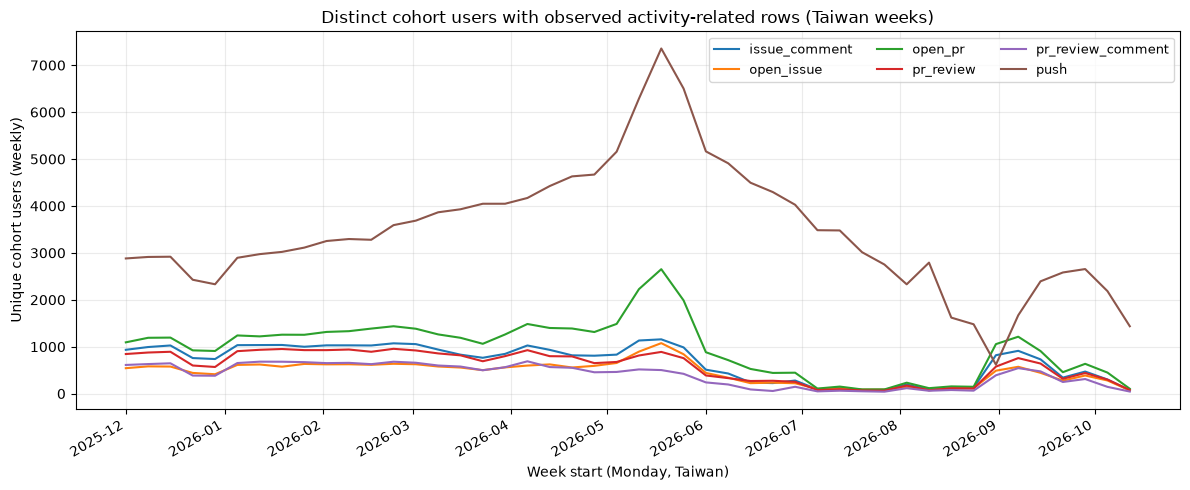

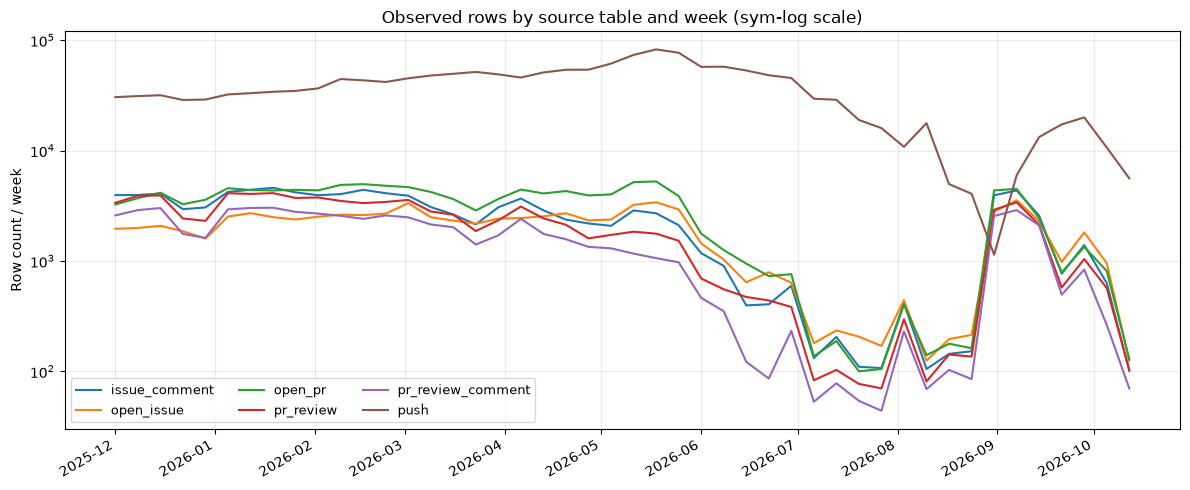

In [7]:
ACTIVITY_SOURCES = {
    "open_pr": ("PullRequests", "author_id", "first_seen_at", None),
    "open_issue": ("Issues", "author_id", "first_seen_at", "is_pull_request"),
    "issue_comment": ("IssueComments", "author_id", "created_at", None),
    "pr_review": ("PRReviews", "reviewer_id", "first_seen_at", None),
    "pr_review_comment": ("PRReviewComments", "author_id", "created_at", None),
    "push": ("Pushes", "user_id", "created_at", None),
}
PROXY_ONLY = {"open_pr", "open_issue", "pr_review"}
activity_weeks = []
for activity, (table, actor, time_col, flag) in ACTIVITY_SOURCES.items():
    columns = [actor, time_col] + ([flag] if flag else [])
    data = read_cols(table, columns)
    if flag:  # Issues table also contains conversations of pull requests
        data = data.loc[data[flag] == False]  # noqa: E712
    data = data.loc[data[actor].isin(cohort_internal_ids), [actor, time_col]].copy()
    data["week_Taiwan"] = local_week_start(data[time_col])
    g = data.dropna(subset=["week_Taiwan"]).groupby("week_Taiwan").agg(
        observed_rows=(actor, "size"), unique_cohort_users=(actor, "nunique")
    ).reset_index()
    g["activity"] = activity
    g["cohort_participation_pct"] = 100 * g["unique_cohort_users"] / max(len(cohort_internal_ids), 1)
    activity_weeks.append(g)
weekly_df = pd.concat(activity_weeks, ignore_index=True)
weekly_df = weekly_df.sort_values(["activity", "week_Taiwan"]).reset_index(drop=True)
display(weekly_df.groupby("activity").agg(
    weeks=("week_Taiwan", "nunique"),
    observed_rows=("observed_rows", "sum"),
    max_weekly_unique_users=("unique_cohort_users", "max"),
).reset_index())

fig, ax = plt.subplots(figsize=(12, 5))
for label, subset in weekly_df.groupby("activity"):
    ax.plot(subset["week_Taiwan"], subset["unique_cohort_users"], label=label)
ax.set_title("Distinct cohort users with observed activity-related rows (Taiwan weeks)")
ax.set_ylabel("Unique cohort users (weekly)")
ax.set_xlabel("Week start (Monday, Taiwan)")
ax.legend(ncol=3, fontsize=9)
ax.grid(alpha=0.25)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
for label, subset in weekly_df.groupby("activity"):
    ax.plot(subset["week_Taiwan"], subset["observed_rows"], label=label)
ax.set_yscale("symlog", linthresh=1)
ax.set_title("Observed rows by source table and week (sym-log scale)")
ax.set_ylabel("Row count / week")
ax.legend(ncol=3, fontsize=9)
ax.grid(alpha=0.25)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

### 7b. Per-user sparsity and recent behavior (baseline feasibility)

Aggregate weekly charts can hide the main difficulty: most users may have **zero** events of a rare type in a short window. The following diagnostic measures how many cohort users have at least one observed row over **7, 30, and 90 days before** the configurable `AUDIT_TIME_TW`. It also shows counts among active users, separately from the full cohort.

For `open_pr`, `open_issue`, and `pr_review`, these counts still represent **row-observation proxies**, not exact activity targets. They are suitable for understanding sparsity but not for claiming validated historical labels.

Audit cutoff: 2026-10-01 00:00:00+08:00 (Taiwan)


,activity_proxy,window_days,cohort_users,positive_users,positive_users_pct,total_rows,median_rows_among_active,max_rows_for_one_user
0,open_pr,7,9000,478,5.31,853,1.0,24
1,open_pr,30,9000,2107,23.41,12517,2.0,149
2,open_pr,90,9000,2394,26.60,14317,2.0,155
3,open_issue,7,9000,297,3.30,1162,1.0,129
4,open_issue,30,9000,1077,11.97,10259,2.0,566
5,open_issue,90,9000,1274,14.16,12383,2.0,613
6,issue_comment,7,9000,348,3.87,855,1.0,64
7,issue_comment,30,9000,1616,17.96,12095,2.0,413
8,issue_comment,90,9000,1821,20.23,13751,2.0,424
9,pr_review,7,9000,343,3.81,634,1.0,24


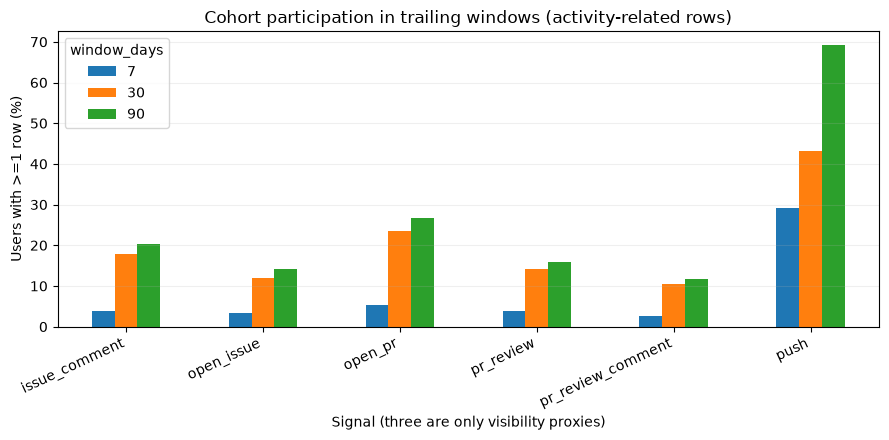

In [8]:
WINDOW_DAYS = (7, 30, 90)
recent_rows = []
recent_by_user = {}
for activity, (table, actor, time_col, flag) in ACTIVITY_SOURCES.items():
    d = read_cols(table, [actor, time_col] + ([flag] if flag else []))
    if flag:
        d = d.loc[d[flag] == False]  # noqa: E712
    times = as_utc(d[time_col])
    d = d.loc[d[actor].isin(cohort_internal_ids) & (times < cutoff_utc)].copy()
    d["row_utc"] = as_utc(d[time_col])
    for n_days in WINDOW_DAYS:
        window_start = cutoff_utc - pd.Timedelta(days=n_days)
        subset = d.loc[d["row_utc"] >= window_start, actor]
        cnt = subset.value_counts().reindex(cohort_internal_ids, fill_value=0)
        recent_by_user[(activity, n_days)] = cnt
        recent_rows.append({
            "activity_proxy": activity,
            "window_days": n_days,
            "cohort_users": len(cnt),
            "positive_users": int((cnt > 0).sum()),
            "positive_users_pct": round(100 * (cnt > 0).mean(), 2),
            "total_rows": int(cnt.sum()),
            "median_rows_among_active": float(cnt[cnt > 0].median()) if (cnt > 0).any() else 0.0,
            "max_rows_for_one_user": int(cnt.max()) if len(cnt) else 0,
        })
recent_df = pd.DataFrame(recent_rows)
print("Audit cutoff:", cutoff_taiwan, "(Taiwan)")
display(recent_df)

fig, ax = plt.subplots(figsize=(9, 4.5))
p = recent_df.pivot(index="activity_proxy", columns="window_days", values="positive_users_pct")
p.plot(kind="bar", ax=ax)
ax.set_title("Cohort participation in trailing windows (activity-related rows)")
ax.set_ylabel("Users with >=1 row (%)")
ax.set_xlabel("Signal (three are only visibility proxies)")
ax.grid(axis="y", alpha=0.2)
plt.xticks(rotation=25, ha="right")
fig.tight_layout()
plt.show()

### 7c. Relational context: repository breadth

A simple and meaningful relational signal is **how many distinct repositories** each cohort developer touched. This is not a relational GNN, but it provides a baseline interpretation for Q2: a user's collaborators and project breadth may add predictive information beyond their own total activity count.

The code below compares distinct repositories for observed **push** and **PR review** rows in the last 30 days. As above, PR review rows are keyed by observation time; no predictive claim is made.

In [9]:
repo_context = []
for label, table, actor, time_col in [
    ("push", "Pushes", "user_id", "created_at"),
    ("pr_review_observed", "PRReviews", "reviewer_id", "first_seen_at"),
]:
    d = read_cols(table, [actor, "repo_id", time_col])
    t = as_utc(d[time_col])
    in_window = (t >= cutoff_utc - pd.Timedelta(days=30)) & (t < cutoff_utc)
    d = d.loc[in_window & d[actor].isin(cohort_internal_ids), [actor, "repo_id"]]
    uniq_repos = d.groupby(actor)["repo_id"].nunique().reindex(cohort_internal_ids, fill_value=0)
    repo_context.append({
        "signal": label,
        "cohort_mean_unique_repos": round(float(uniq_repos.mean()), 3),
        "cohort_median_unique_repos": float(uniq_repos.median()),
        "users_touched_multiple_repos": int((uniq_repos >= 2).sum()),
        "max_unique_repos_single_user": int(uniq_repos.max()),
    })
display(pd.DataFrame(repo_context))

,signal,cohort_mean_unique_repos,cohort_median_unique_repos,users_touched_multiple_repos,max_unique_repos_single_user
0,push,1.066,0.0,1903,53
1,pr_review_observed,0.239,0.0,414,25


## 8. Missingness and useful column categories

Missing values are expected in some data: e.g., `PullRequests.author_id` may be null when an older PR was not observed when opened; `Issues.assignee_id` is naturally optional. Missing values in **primary keys or required time columns** are much more concerning.

To avoid reading large free-text fields, this cell measures **exact missingness for selected structural/time columns only**. It is an audit of these columns, *not* all attributes in the schema.

In [10]:
COLUMN_AUDIT = {
    "Users": ["user_id", "github_user_id", "is_cohort", "is_bot", "first_seen_at"],
    "Repositories": ["repo_id", "github_repo_id", "first_seen_at", "org_id"],
    "PullRequests": ["pr_id", "repo_id", "author_id", "merged_by_id", "created_at", "first_seen_at", "closed_at", "merged_at"],
    "Issues": ["issue_id", "repo_id", "author_id", "assignee_id", "pull_request_id", "is_pull_request", "created_at", "first_seen_at", "closed_at", "state_reason"],
    "IssueComments": ["comment_id", "issue_id", "repo_id", "author_id", "created_at"],
    "PRReviews": ["review_id", "pr_id", "repo_id", "reviewer_id", "submitted_at", "first_seen_at", "dismissed_at"],
    "PRReviewComments": ["comment_id", "pr_id", "repo_id", "author_id", "pull_request_review_id", "in_reply_to_id", "created_at"],
    "Pushes": ["push_id", "user_id", "repo_id", "created_at", "is_new_ref", "ref_type"],
}
null_stats = []
for table, candidates in COLUMN_AUDIT.items():
    subset = [c for c in candidates if c in parquet_columns[table]]
    d = read_cols(table, subset)
    for c in subset:
        null_stats.append({"table": table, "column": c, "missing_n": int(d[c].isna().sum()),
                           "missing_pct": round(100*d[c].isna().mean(), 2),
                           "rows": len(d)})
null_df = pd.DataFrame(null_stats)
display(null_df.sort_values(["table", "missing_pct"], ascending=[True, False]).reset_index(drop=True))

,table,column,missing_n,missing_pct,rows
0,IssueComments,comment_id,0,0.00,106204
1,IssueComments,issue_id,0,0.00,106204
2,IssueComments,repo_id,0,0.00,106204
3,IssueComments,author_id,0,0.00,106204
4,IssueComments,created_at,0,0.00,106204
5,Issues,pull_request_id,156564,91.02,172007
6,Issues,assignee_id,132055,76.77,172007
7,Issues,state_reason,117250,68.17,172007
8,Issues,closed_at,103198,60.00,172007
9,Issues,issue_id,0,0.00,172007


## 9. Creation time versus row visibility: label feasibility diagnostics

This is one of the most important findings to establish *before* writing the temporal dataset builder.

- `PullRequests.created_at`: when PR was opened (if known).
- `Issues.created_at`: original issue creation; may precede first cohort-relevant observation.
- `PRReviews.submitted_at`: review submission; can predate its first appearance in these tables.
- `first_seen_at`: earliest event through which the **row became observable**.

A row observed this week is not necessarily an activity **performed** this week. Therefore simply grouping `first_seen_at` and claiming the result is `open_pr` / `open_issue` / `pr_review` labels can mislabel old entities. The PDF specifies targets but not an unambiguous SQL-style historical-label derivation recipe for these cases. Review official task definitions and observed data before finalizing a labeling policy; record ambiguous cases rather than inventing certainty.

The following quantifies discrepancies without asserting that one timestamp alone is an exact label.

,table,candidate_event_time,records,paired_timestamps,event_time_missing_pct,first_seen_later_gt_24h_pct,first_seen_later_gt_7d_pct,negative_lag_pct,median_lag_hours
0,PullRequests,created_at,301518,135077,55.2,4.66,2.27,0.0,0.00
1,Issues,created_at,172007,172007,0.0,34.71,20.99,0.0,2.12
2,PRReviews,submitted_at,90710,90710,0.0,0.45,0.13,0.0,0.00


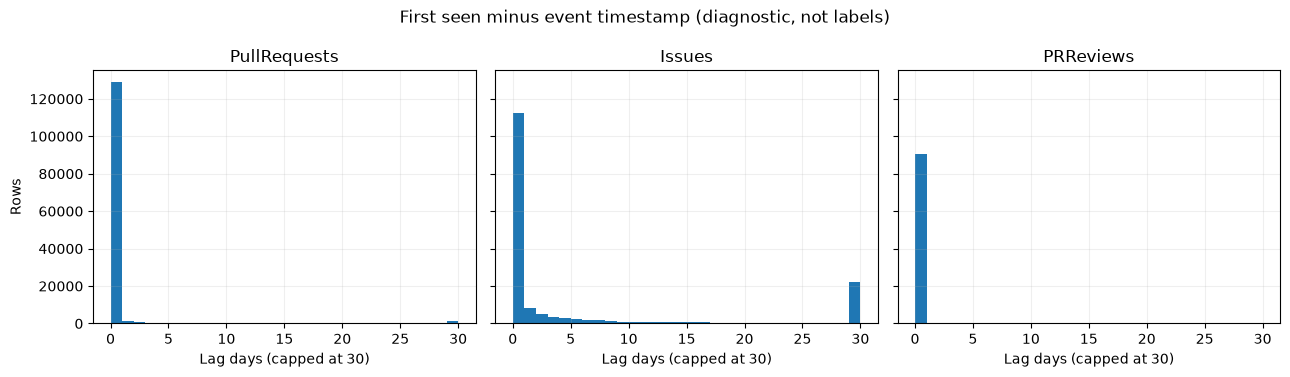

In [11]:
DATE_PAIRS = {
    "PullRequests": ("created_at", "first_seen_at"),
    "Issues": ("created_at", "first_seen_at"),
    "PRReviews": ("submitted_at", "first_seen_at"),
}
visibility_rows = []
for table, (event_col, seen_col) in DATE_PAIRS.items():
    df = read_cols(table, [event_col, seen_col])
    evt, seen = as_utc(df[event_col]), as_utc(df[seen_col])
    lag = (seen - evt).dt.total_seconds() / 3600
    valid = lag.dropna()
    visibility_rows.append({
        "table": table, "candidate_event_time": event_col,
        "records": len(df), "paired_timestamps": len(valid),
        "event_time_missing_pct": round(100 * evt.isna().mean(), 2),
        "first_seen_later_gt_24h_pct": round(100 * (valid > 24).mean(), 2) if len(valid) else np.nan,
        "first_seen_later_gt_7d_pct": round(100 * (valid > 168).mean(), 2) if len(valid) else np.nan,
        "negative_lag_pct": round(100 * (valid < 0).mean(), 2) if len(valid) else np.nan,
        "median_lag_hours": round(float(valid.median()), 2) if len(valid) else np.nan,
    })
visibility_df = pd.DataFrame(visibility_rows)
display(visibility_df)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (table, (event_col, seen_col)) in zip(axes, DATE_PAIRS.items()):
    df = read_cols(table, [event_col, seen_col])
    lag_days = (as_utc(df[seen_col]) - as_utc(df[event_col])).dt.total_seconds().div(86400)
    lag_days = lag_days.replace([np.inf, -np.inf], np.nan).dropna()
    positive = lag_days.clip(lower=0, upper=30)
    ax.hist(positive, bins=30)
    ax.set_title(table)
    ax.set_xlabel("Lag days (capped at 30)")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Rows")
fig.suptitle("First seen minus event timestamp (diagnostic, not labels)")
fig.tight_layout()
plt.show()

## 10. Historical cutoff and fields known only later

For **features** at an arbitrary prediction cutoff `t`, include rows only if their **official row time** is strictly before `t`. Also guard the six late-known fields:

```text
PullRequests.merged_at, PullRequests.merged_by_id, PullRequests.closed_at
Issues.closed_at, Issues.state_reason
PRReviews.dismissed_at
```

Important nuance: some late-known fields are **not timestamps** (`merged_by_id`, `state_reason`). A value in a final snapshot cannot be assumed available at an earlier `t` unless its acquisition time is established. A conservative safe baseline simply *excludes* these late-known fields from historical feature generation.

For EDA we compare the number of rows visible at a chosen historical cutoff; this is a **diagnostic**, not a final training/validation split.

In [12]:
cutoff_audit = []
for table in TABLES:
    t = as_utc(read_cols(table, [ROW_TIME[table]])[ROW_TIME[table]])
    cutoff_audit.append({
        "table": table, "total_rows": len(t),
        "rows_visible_before_cutoff": int((t < cutoff_utc).sum()),
        "rows_not_yet_visible": int((t >= cutoff_utc).sum()),
        "missing_time": int(t.isna().sum()),
    })
print("Cutoff Taiwan:", cutoff_taiwan)
print("Cutoff UTC:   ", cutoff_utc)
display(pd.DataFrame(cutoff_audit))

late_time_fields = [
    ("PullRequests", "merged_at"),
    ("PullRequests", "closed_at"),
    ("Issues", "closed_at"),
    ("PRReviews", "dismissed_at"),
]
late_rows = []
for table, col in late_time_fields:
    d = read_cols(table, [ROW_TIME[table], col])
    eligible_rows = as_utc(d[ROW_TIME[table]]) < cutoff_utc
    late_event_time = as_utc(d[col])
    late_rows.append({
        "table": table, "late_known_field": col,
        "rows_visible_at_cutoff": int(eligible_rows.sum()),
        "currently_filled_in_visible_rows": int((eligible_rows & late_event_time.notna()).sum()),
        "would_leak_if_used_as_is": int((eligible_rows & (late_event_time >= cutoff_utc)).sum()),
    })
display(pd.DataFrame(late_rows))
print("DO NOT use final-snapshot late-known values in historical features without cutoff masking.")

Cutoff Taiwan: 2026-10-01 00:00:00+08:00
Cutoff UTC:    2026-09-30 16:00:00+00:00


,table,total_rows,rows_visible_before_cutoff,rows_not_yet_visible,missing_time
0,Users,45590,45221,369,0
1,Repositories,109081,107216,1865,0
2,PullRequests,301518,296037,5481,0
3,Issues,172007,168481,3526,0
4,IssueComments,106204,104581,1623,0
5,PRReviews,90710,89354,1356,0
6,PRReviewComments,66422,65512,910,0
7,Pushes,1661256,1633385,27871,0


,table,late_known_field,rows_visible_at_cutoff,currently_filled_in_visible_rows,would_leak_if_used_as_is
0,PullRequests,merged_at,296037,103550,8
1,PullRequests,closed_at,296037,110690,8
2,Issues,closed_at,168481,67647,25
3,PRReviews,dismissed_at,89354,1339,0


DO NOT use final-snapshot late-known values in historical features without cutoff masking.


## 11. Official evaluation files (when available)

The TAs plan to publish `assignment2/evaluation/test_input.csv` on **Oct 28**. It has one column, `UserID`, which is `Users.github_user_id` (NOT `Users.user_id`). The official repo describes a test-eligibility rule based on >=5 records during the 90 days before the Oct 28 20:00 Taiwan snapshot.

This cell automatically recognizes the file **once it appears in a refreshed clone**. It does not download files or invent user IDs, and it does not create an output CSV.

Before final submission, `evaluate.py` enforces exact column names/order, no duplicate/missing/extra testing users, only `0/1`, and no blank cells. Formatting errors invalidate the entire **7%** prediction component.

In [13]:
test_file = OFFICIAL_REPO / "evaluation" / "test_input.csv"
if test_file.is_file():
    test_users = pd.read_csv(test_file, dtype={"UserID": "int64"})
    assert list(test_users.columns) == ["UserID"], "Unexpected test_input header"
    print("Official test users:", len(test_users))
    print("Duplicated test UserIDs:", int(test_users["UserID"].duplicated().sum()))
    print("Not in Users.github_user_id:", int((~test_users["UserID"].isin(users["github_user_id"])).sum()))
    print("Not marked is_cohort:", int((~test_users["UserID"].isin(cohort_github_ids)).sum()))
    display(test_users.head(5))
else:
    print("test_input.csv not found in this snapshot (scheduled for Oct 28). This is expected before release.")

test_input.csv not found in this snapshot (scheduled for Oct 28). This is expected before release.


## 12. What changes from one daily snapshot to the next?

The optional history file logs a **compact audit record** of each distinct local snapshot. The record includes Git SHA (if present), file sizes, row counts, latest row timestamp, and structural integrity totals. It stores **no user-level data**.

The notebook does **not** assume a new data release exists just because the clock is later than 21:00. To observe changes, **re-clone the updated official repository first**, then restart and run this notebook.

If you do not want the notebook to write any files, set `SAVE_RELEASE_HISTORY=False` in Section 1.

In [14]:
snapshot_summary = {
    "fingerprint": SNAPSHOT_FINGERPRINT,
    "official_repo_sha": REPO_SHA,
    "observed_at_utc": datetime.now(timezone.utc).isoformat(),
    "source": str(DATA_DIR),
    "table_rows": {r["table"]: int(r["rows"]) for r in meta_rows},
    "table_bytes": {r["table"]: int(r["bytes"]) for r in meta_rows},
    "max_row_time_utc": {
        str(r["table"]): (r["max_UTC"].isoformat() if pd.notna(r["max_UTC"]) else None)
        for r in coverage
    },
    "cohort_users": int(len(cohort_users)),
    "non_null_orphan_fk_references": int(fk_audit_df["orphan_references"].sum()),
    "pk_duplicates": int(pk_audit_df["PK_duplicates"].sum()),
}

existing_history = []
if HISTORY_PATH.exists():
    for line in HISTORY_PATH.read_text(encoding="utf-8").splitlines():
        if line.strip():
            try:
                existing_history.append(json.loads(line))
            except json.JSONDecodeError:
                print("Warning: skipping a malformed snapshot-history line")

previous = existing_history[-1] if existing_history else None
if previous is not None:
    old_counts = previous.get("table_rows", {})
    diff = pd.DataFrame([{
        "table": t,
        "previous_rows": old_counts.get(t),
        "current_rows": snapshot_summary["table_rows"][t],
        "change": snapshot_summary["table_rows"][t] - old_counts[t] if t in old_counts else np.nan,
    } for t in TABLES])
    print("Change since previously LOGGED release:")
    display(diff)
    if previous.get("fingerprint") == SNAPSHOT_FINGERPRINT:
        print("Same fingerprint as the latest logged release; no duplicate log entry will be written.")
else:
    print("No previous local snapshot recorded. Today's run can become the first baseline.")

if SAVE_RELEASE_HISTORY and not any(
    rec.get("fingerprint") == SNAPSHOT_FINGERPRINT for rec in existing_history
):
    HISTORY_PATH.parent.mkdir(parents=True, exist_ok=True)
    with HISTORY_PATH.open("a", encoding="utf-8") as f:
        f.write(json.dumps(snapshot_summary, ensure_ascii=False) + "\n")
    print("Saved new release fingerprint to:", HISTORY_PATH)
else:
    print("Snapshot log unchanged (logging disabled or release already recorded).")

No previous local snapshot recorded. Today's run can become the first baseline.
Saved new release fingerprint to: c:\Users\Davon\Desktop\Master\Semester 3\535703 Big Data Analytics\Assignment 2\experiments\eda_snapshot_history.jsonl


## 13. What EDA establishes — and what still needs to be designed

After inspecting your results, write a short note on:

1. **Cohort:** number of marked cohort users; bots and other referenced users.
2. **Data integrity:** PK uniqueness, orphan FK counts, missing critical timestamp values.
3. **Time coverage:** most recent observable event for each table; whether the current week is incomplete.
4. **Behavior:** dominant event types, sparsity, weekly volatility, and differences between unique-user and total-row counts.
5. **Label uncertainty:** frequency of `created_at` / `submitted_at` lagging behind `first_seen_at`. Identify ambiguous PR/issue/review cases before committing to historical labels.
6. **Release drift:** row count changes across daily releases and whether sample identities were renumbered.
7. **Model implications:** a frequency/recency baseline, then relational and temporal enhancements for Q2/Q3.

### Next engineering milestone (separate module, not hidden inside this notebook)

```text
Official eight tables + stable cohort GitHub IDs
                       |
                       v
         Historical prediction cutoff t
                       |
          +------------+-------------+
          |                          |
          v                          v
Features: only observable       Labels: actual activities
records & values before t       during [t, t+7 days)
          |                          |
          +------------+-------------+
                       v
              (UserID, t, X, y)
                       |
              temporal partitions
                       v
            TRAIN → VALIDATE → TEST
```

**Crucial:** A final dataset snapshot can include retrospectively discovered records. When building historical examples, enforce the official row times, handle late-known attributes, and acknowledge that full original event provenance may not be present for some activity types. Do not treat this EDA's first-seen proxies as definitive target labels.

**Recommended checks before training:** stable IDs, no duplicate `(UserID, cutoff)` examples, strict cutoff comparisons, non-overlapping label windows where appropriate, temporal holdout, per-label positive rates, and evaluation parity with official `evaluate.py`.

**Course policy:** You may use AI to discuss and improve ideas, but your work and experiment claims must be authentic. AI-generated presentation videos are forbidden; plagiarism results in zero credit.

## Appendix — Interpretation and implementation notes

- **A full `Users` table has more than 9,000 rows** because referenced GitHub users are also represented. Use `is_cohort` for supervised cohort analysis; preserve all required test IDs.
- **A PR is also an issue for discussion purposes.** `Issues.is_pull_request=True` records PR-conversation issues; exclude them when examining new non-PR issues.
- **FK values are internal row numbers.** Recompute joins after each data refresh; never persist cross-release joins using only `user_id` or `repo_id`.
- **Time zones:** local release schedule is Asia/Taipei; Parquet timestamps are naive UTC. The official prediction interval begins **2026-11-11 16:00 UTC**.
- **Incomplete weeks:** the newest week usually contains fewer than seven days of observations; compare full weeks for trend analysis.
- **Source of truth:** the assignment PDF, data README, SCHEMA.md, and evaluation README override any illustrative suggestion in this notebook. If these files change, update the notebook's source-derived definitions and document the change.
- **Scope:** this EDA is diagnostic. Its observational plots must not be cited as model performance, validation scores, or correctly reconstructed ground truth.
- **Performance:** Parquet metadata is read cheaply; full-table scans project only required columns. On a memory-limited laptop, run cells sequentially and avoid loading free-text columns into memory.